# Chronos-2 with the wind forecast

**What this notebook does:** gives Chronos-2 one more series besides the price: EirGrid's wind forecast, *as it stood before each auction*. It then runs the same day-by-day test as notebook 01 and compares the model with and without wind.

**Before running:** as for notebook 01 (`pip install -e ".[foundation,notebooks]"`, isem-data next to this project). isem-data must have the per-farm wind forecasts in `data/wind_unit_forecasts/`, which it has kept since August 2026.

## Covariates, in plain words

A **covariate** is another series that helps forecast the one you care about. Wind is the obvious one for Irish prices: lots of wind means cheap power, so the price falls.

Chronos-2 takes covariates as two pieces:

- **the past:** the covariate's values over the same weeks as the price history it is shown, so it can see how the price moved with it;
- **the future:** the covariate's values for the day being forecast, so it can use what it saw.

Only a series whose future values are *known when you forecast* can go in the future piece. Tomorrow's actual wind isn't known; tomorrow's wind *forecast* is.

## The trap: which wind forecast?

EirGrid revises its wind forecast about four times a day. The day-ahead auction for day D closes at 11:00 Irish time on D-1. Any revision after that is information no trader had.

isem-data's `wind.parquet` keeps only EirGrid's **latest** revision. Using it would quietly let the model peek. So this notebook builds the forecast as it stood before each auction from SEMO's per-farm forecasts (report BM-012), which isem-data keeps **every version** of:

1. For delivery day D, take the newest version published by **09:00 UTC on D-1**. That is at least an hour before the auction in summer and winter, and still safe if SEMO's publish times are an hour off.
2. Add up all the farms to get one all-island number per half-hour.
3. If no version came out that morning, use the newest older one (up to two days older). It's still a forecast a trader had.

`wind_forecast_before_auction()` in `data.py` does exactly this, and `tests/test_data.py` checks it.

In [1]:
import warnings
from datetime import timedelta

import matplotlib.pyplot as plt
import pandas as pd

from isem_forecast.baselines import BASELINES
from isem_forecast.data import (
    delivery_day,
    load_prices,
    load_wind,
    wind_forecast_before_auction,
    wind_forecast_versions,
)
from isem_forecast.evaluate import errors, mae_by_month, summary, walk_forward
from isem_forecast.foundation import Chronos2, load_model, share_inside

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 1)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

prices = load_prices()
wind = load_wind()  # measured output, and EirGrid's latest revision
honest = wind_forecast_before_auction()  # the version known before each auction
first, last = min(delivery_day(honest.index)), max(delivery_day(honest.index))
print(f"Wind forecasts known before the auction: delivery days {first} to {last}")
honest.head()

Wind forecasts known before the auction: delivery days 2026-08-12 to 2026-11-18


,forecast_mw,published_utc
timestamp_utc,,
2026-08-11 22:00:00+00:00,1233.4,2026-08-11 06:14:25+00:00
2026-08-11 22:30:00+00:00,1250.2,2026-08-11 06:14:25+00:00
2026-08-11 23:00:00+00:00,1261.5,2026-08-11 06:14:25+00:00
2026-08-11 23:30:00+00:00,1256.3,2026-08-11 06:14:25+00:00
2026-08-12 00:00:00+00:00,1247.6,2026-08-11 06:14:25+00:00


## One day, several versions

Every version of the forecast for one delivery day, against what the farms produced. The thick line is the one the model gets. Later versions were usually closer to the outcome, but they came too late.

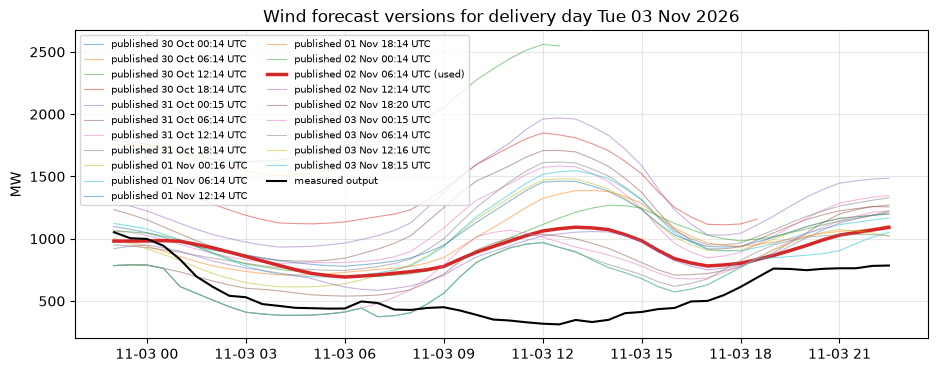

In [2]:
versions = wind_forecast_versions()
day = pd.Timestamp("2026-11-03").date()
targets = prices.index[delivery_day(prices.index) == day]
chosen = honest["published_utc"][targets[0]]

ax = plt.gca()
for published, version in sorted(versions.items()):
    part = version.reindex(targets)
    if part.isna().all() or published > targets[-1]:
        continue
    used = published == chosen
    ax.plot(
        targets.tz_convert("Europe/Dublin"),
        part.values,
        lw=2.5 if used else 0.8,
        alpha=1 if used else 0.5,
        label=f"published {published:%d %b %H:%M} UTC" + (" (used)" if used else ""),
    )
ax.plot(
    targets.tz_convert("Europe/Dublin"),
    wind["actual_mw"].reindex(targets).values,
    color="black",
    lw=1.5,
    label="measured output",
)
ax.set_ylabel("MW")
ax.set_title(f"Wind forecast versions for delivery day {day:%a %d %b %Y}")
ax.legend(fontsize=7, ncol=2)
plt.show()

The measured output can sit below every forecast: it is what the farms produced *after* dispatch-down, while the forecast is what they could have produced.

## The test

Four versions of Chronos-2, each shown the last 28 days, on the same days:

| Name | Past | Future |
|---|---|---|
| `prices_only` | prices | nothing |
| `wind` | prices + wind forecast before the auction | wind forecast before the auction |
| `measured_past` | prices + measured wind output | wind forecast before the auction |
| `peeking` | prices + EirGrid's latest revision | EirGrid's latest revision (not allowed live) |

`measured_past` asks whether the past should hold what actually happened or the forecast. `peeking` shows how much the trap would have flattered the result.

The test starts once a whole month of forecasts is available, so every model sees a complete past.

In [3]:
model = load_model()
start, end = first + timedelta(days=28), max(delivery_day(prices.index))

# Measured wind and the latest revision miss a few values around the October clock change.
# Fill those short gaps, or every day whose month of history touches them would be skipped.
measured = wind["actual_mw"].interpolate(limit=4, limit_area="inside")
latest = wind["latest_forecast_mw"].interpolate(limit=4, limit_area="inside")

models = {
    "prices_only": Chronos2(model, 28),
    "wind": Chronos2(model, 28, {"wind": honest["forecast_mw"]}),
    "peeking": Chronos2(model, 28, {"wind": latest}),
}


class MeasuredPast(Chronos2):
    # Measured wind for the past, the forecast before the auction for the day ahead.
    def __call__(self, history, targets):
        past = measured.index < targets[0]
        self.covariates = {"wind": measured.where(past, honest["forecast_mw"])}
        return super().__call__(history, targets)


models["measured_past"] = MeasuredPast(model, 28)

results = {"week_average": walk_forward(prices, BASELINES["week_average"], start, end)}
for name, forecaster in models.items():
    results[name] = walk_forward(prices, forecaster, start, end)

common = errors(results).index
print(
    f"Delivery days {start} to {end}: {len(set(delivery_day(common)))} days, "
    f"{len(common):,} half-hours, the same for every method"
)
table = summary(results)
table["inside 80% range"] = [
    f"{share_inside(models[m].ranges().reindex(common), prices):.0%}" if m in models else ""
    for m in table.index
]
table

W1116 23:19:03.324000 16884 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Delivery days 2026-09-09 to 2026-11-14: 67 days, 3,218 half-hours, the same for every method


,MAE,RMSE,inside 80% range
peeking,35.6,50.9,71%
wind,36.5,53.2,72%
measured_past,40.2,57.9,70%
prices_only,46.9,67.5,70%
week_average,66.3,87.8,


In [4]:
mae_by_month(results)

,week_average,prices_only,wind,peeking,measured_past
2026-09,47.1,37.9,28.1,30.6,33.5
2026-10,63.8,44.4,32.8,31.8,35.2
2026-11,102.3,66.5,58.0,51.7,62.0


## Where the wind forecast helps

Each day's average miss, with and without wind. Points below the diagonal are days the wind forecast helped.

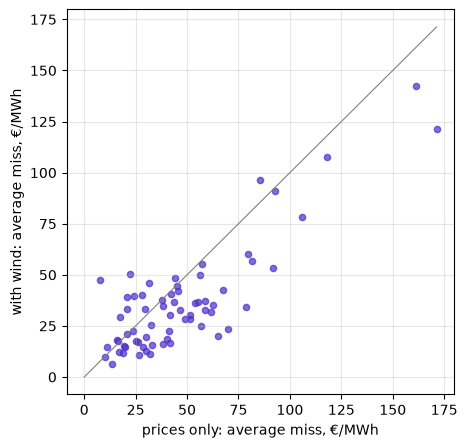

The wind forecast helped on 76% of days


In [5]:
by_day = errors(results).abs().groupby(delivery_day(common)).mean()
ax = by_day.plot.scatter(x="prices_only", y="wind", alpha=0.7, color="#4b2fc9", figsize=(5, 5))
top = by_day[["prices_only", "wind"]].max().max()
ax.plot([0, top], [0, top], color="grey", lw=0.8)
ax.set_xlabel("prices only: average miss, €/MWh")
ax.set_ylabel("with wind: average miss, €/MWh")
plt.show()
helped = (by_day["wind"] < by_day["prices_only"]).mean()
print(f"The wind forecast helped on {helped:.0%} of days")

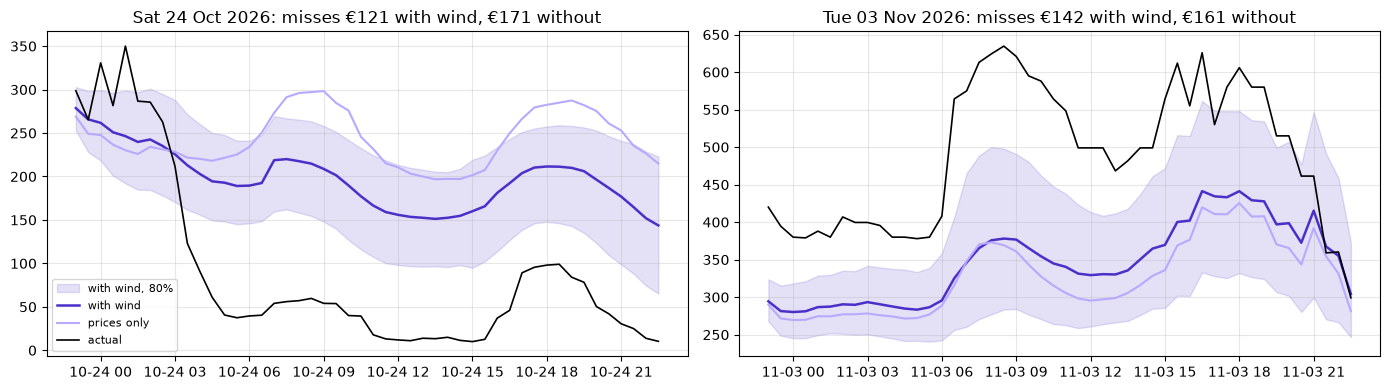

In [6]:
def plot_day(day, ax):
    targets = common[delivery_day(common) == day]
    t = targets.tz_convert("Europe/Dublin")
    band = models["wind"].ranges().reindex(targets)
    purple = "#4b2fc9"
    ax.fill_between(t, band["low"], band["high"], color=purple, alpha=0.15, label="with wind, 80%")
    ax.plot(t, band["median"], color=purple, lw=1.8, label="with wind")
    alone = results["prices_only"]["forecast"].reindex(targets)
    ax.plot(t, alone, color="#b8a9ff", label="prices only")
    ax.plot(t, prices[targets], color="black", lw=1.2, label="actual")
    ax.set_title(
        f"{day:%a %d %b %Y}: misses €{by_day.loc[day, 'wind']:.0f} with wind, "
        f"€{by_day.loc[day, 'prices_only']:.0f} without"
    )


gain = by_day["prices_only"] - by_day["wind"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_day(gain.idxmax(), axes[0])  # where wind helped most
plot_day(by_day["wind"].idxmax(), axes[1])  # its worst day
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## What this shows

From the first run on 16 Nov 2026, delivery days 9 Sep to 14 Nov 2026 (67 days):

- **The wind forecast cuts the average miss by about a fifth:** €36.5/MWh against €46.9 on prices alone, and €66.3 for `week_average`. It was better in each of the three months, and on about three days in four.
- **The past should hold the forecast, not what happened.** Giving it measured wind for the past scored €40.2, worse. The model learns how the price moved with the *forecast*, the same kind of number it gets for tomorrow. Measured output is also a different thing: it is after dispatch-down.
- **Peeking would have flattered it only a little:** €35.6 with EirGrid's latest revision. The morning-before forecast is nearly as useful here. The rule still matters: with other inputs, or other days, the gap could be large.
- **Its range is still a little overconfident:** the price landed inside the 80% range about 72% of the time.
- **The worst days are surprises the forecast didn't see either.** On 3 Nov the version used expected about 1,000 MW at midday; the farms produced about 400 MW, and the price went far above every forecast.

Read with care: 67 days is short and was mostly a stormy autumn. The four versions were compared on the same days that picked the winner, so its margin over the other three flatters it a little. And the comparison is still with simple methods only.

## Next

- **A proper statistical model on the same days.** LightGBM or LEAR, given the same wind forecast and the calendar. Until then Chronos-2 has only beaten simple methods.
- **More known-future inputs.** EirGrid's demand forecast (needs every version kept, like wind), and interconnector flows.
- **Honest ranges.** Conformal prediction widens the 80% range until it really holds 80% of the time.

The results also feed Open Power Lab's Price forecasts page: `python -m isem_forecast.site --out <the site's src/forecasts/data/chronos>`.